# Country Segmentation Using Unsupervised Learning

- This project is part of the NF3 assignment for the *Machine Learning Systems* course.
- The objective is to group countries based on patterns and similarities in their data. An unsupervised learning model is used to identify these groups, known as *clusters*.

## Practical Application

Grouping countries by their socioeconomic indicators can help identify countries with similar profiles and use them as reference points when comparing health, economic, or trade indicators. For example, it can reveal which countries stand out for their trade activity relative to GDP and how they differ from other high-income countries.

## Dataset

- Kaggle: [Unsupervised Learning on Country Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data)

## Variable Descriptions

The descriptions are based on `data-dictionary.csv`, provided by the dataset creator.

| Variable | Description |
|---|---|
| `country` | Country name. |
| `child_mort` | Deaths of children under five per 1,000 live births. |
| `exports` | Exports per capita as a percentage of GDP per capita. |
| `health` | Health spending per capita as a percentage of GDP per capita. |
| `imports` | Imports per capita as a percentage of GDP per capita. |
| `income` | Net income per person. |
| `inflation` | Indicator labeled as inflation, whose definition is unclear. |
| `life_expec` | Life expectancy at birth, in years. |
| `total_fer` | Estimated number of children per woman. |
| `gdpp` | GDP per capita. |

The numerical variables are used for training, except for `inflation`, because its exact meaning could not be confirmed. The `country` column is retained to identify countries in the results.

The units and reference period of some indicators, such as `income` and `gdpp`, should be verified against the original source.

### Libraries Used

- pandas
- Seaborn
- Matplotlib
- scikit-learn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv('archive/Country-data.csv')

print(df.describe())

       child_mort     exports      health     imports         income  \
count  167.000000  167.000000  167.000000  167.000000     167.000000   
mean    38.270060   41.108976    6.815689   46.890215   17144.688623   
std     40.328931   27.412010    2.746837   24.209589   19278.067698   
min      2.600000    0.109000    1.810000    0.065900     609.000000   
25%      8.250000   23.800000    4.920000   30.200000    3355.000000   
50%     19.300000   35.000000    6.320000   43.300000    9960.000000   
75%     62.100000   51.350000    8.600000   58.750000   22800.000000   
max    208.000000  200.000000   17.900000  174.000000  125000.000000   

        inflation  life_expec   total_fer           gdpp  
count  167.000000  167.000000  167.000000     167.000000  
mean     7.781832   70.555689    2.947964   12964.155689  
std     10.570704    8.893172    1.513848   18328.704809  
min     -4.210000   32.100000    1.150000     231.000000  
25%      1.810000   65.300000    1.795000    1330.000000

### Exploratory Data Analysis (EDA)

- **Rows:** 167.
- **Columns:** 10.
- **Missing values:** None.
- **Duplicate rows:** None.
- **Data types:** Seven `float64` variables (`child_mort`, `exports`, `health`, `imports`, `inflation`, `life_expec`, and `total_fer`), one string variable (`country`), and two `int64` variables (`income` and `gdpp`).

In [2]:
print(f"Dataset shape (rows, columns): {df.shape}\n")
print(f"Missing values:\n{df.isna().sum()}\n")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate country names: {df['country'].duplicated().sum()}")

Dataset shape (rows, columns): (167, 10)

Missing values:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Duplicate rows: 0
Duplicate country names: 0


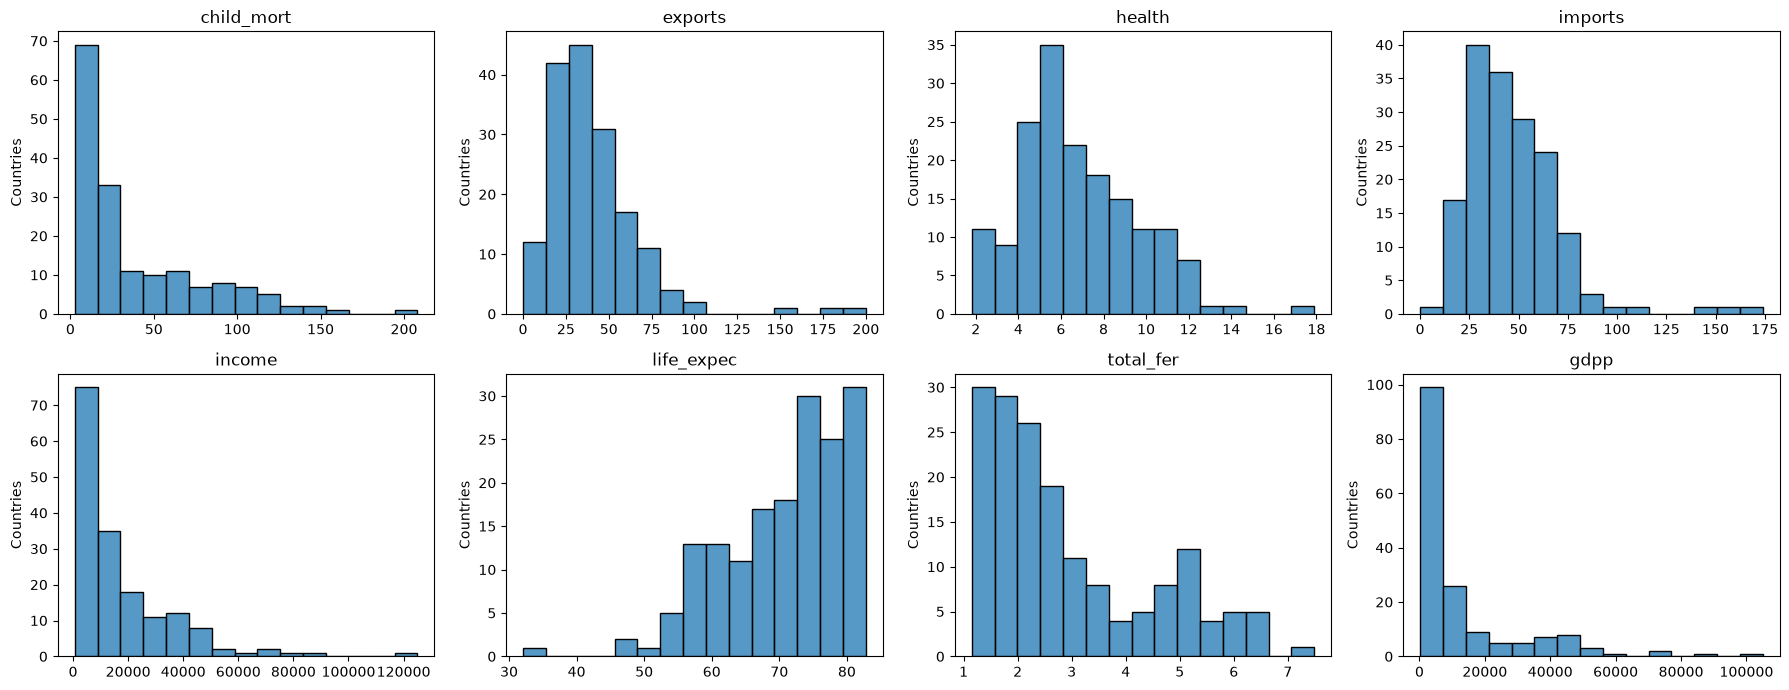

In [3]:
indicadores = df.drop(columns=["country", "inflation"])

fig, ejes = plt.subplots(2, 4, figsize=(18, 7))

for columna, eje in zip(indicadores.columns, ejes.ravel()):
    sns.histplot(data=indicadores, x=columna, bins=15, ax=eje)
    eje.set_title(columna)
    eje.set(xlabel="", ylabel="Countries")

plt.tight_layout()
plt.show()

- **`child_mort`:** The distribution is right-skewed. The first few bins contain the most observations, and frequencies drop quickly as values increase. There is a long right tail and an isolated value around 200.

- **`exports`:** The distribution is right-skewed. Most countries fall between 0 and 100, with much lower frequencies beyond that range and isolated values around 150 and 200.

- **`health`:** The distribution is right-skewed. Observations are concentrated between 3 and 10, with frequencies generally decreasing beyond 5–6. There are isolated values around 18.

- **`imports`:** The distribution is right-skewed. Most observations fall between 10 and 80, with the highest concentration around 25. There are isolated values around 150.

- **`income`:** The distribution is right-skewed. The first bin contains the largest number of countries. Frequencies generally decrease across the remaining bins, with a few local increases and isolated values above 120,000.

- **`life_expec`:** The distribution is left-skewed. The tallest bars are roughly between 75 and 85 years. A few low values lie well apart from the main concentration.

- **`total_fer`:** The distribution is right-skewed. Most observations fall between 1 and 3 children per woman. The right tail shows a small increase in frequency around 5.

- **`gdpp`:** The distribution is right-skewed. The first bin contains most countries, and frequencies drop sharply across the following bins. A few isolated values appear at the upper end of the distribution.

### EDA Summary

The dataset contains 167 countries and has no missing values or duplicate rows, so there was no need to impute values or remove rows on those grounds. The histograms show extreme values, particularly in `exports`, `imports`, `income`, and `gdpp`. I retained them because an unusual value can reflect a meaningful characteristic of a country and does not necessarily indicate an error. The clustering analysis later showed that Luxembourg, Malta, and Singapore form a group with particularly high exports and imports relative to GDP.

*The 10 Countries with the Highest GDP per Capita*

In [4]:
df.nlargest(10, "gdpp")[["country", "gdpp", "income"]]

,country,gdpp,income
91,Luxembourg,105000,91700
114,Norway,87800,62300
145,Switzerland,74600,55500
123,Qatar,70300,125000
44,Denmark,58000,44000
144,Sweden,52100,42900
7,Australia,51900,41400
110,Netherlands,50300,45500
73,Ireland,48700,45700
159,United States,48400,49400


*The 10 Countries with the Highest Net Income per Person*

In [5]:
df.nlargest(10,"income")[['country','income','gdpp']]

,country,income,gdpp
123,Qatar,125000,70300
91,Luxembourg,91700,105000
23,Brunei,80600,35300
82,Kuwait,75200,38500
133,Singapore,72100,46600
114,Norway,62300,87800
157,United Arab Emirates,57600,35000
145,Switzerland,55500,74600
159,United States,49400,48400
73,Ireland,45700,48700


**Observations:** Luxembourg has the highest GDP per capita in the dataset (`gdpp` = 105,000). However, ranking countries by GDP per capita does not necessarily produce the same order as ranking them by net income per person. For example, Qatar ranks fourth in GDP per capita, at 70,300, but has the highest net income per person, at 125,000. The two indicators capture different aspects of the economy: one measures output per person, while the other measures net income per person.

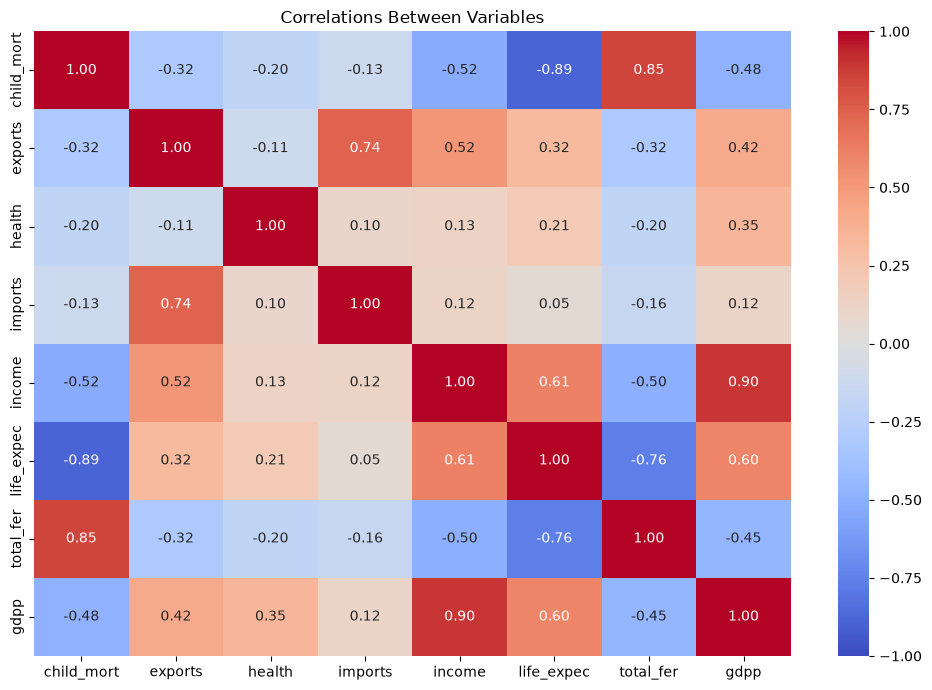

In [6]:
indicadores = df.drop(columns=["country", "inflation"])

plt.figure(figsize=(10, 7))
sns.heatmap(
    indicadores.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlations Between Variables")
plt.tight_layout()
plt.show()

**Correlations between variables**

The strongest positive correlations highlighted here are between `income` and `gdpp` (0.90) and between `child_mort` and `total_fer` (0.85). There are also strong negative correlations between `child_mort` and `life_expec` (−0.89) and between `total_fer` and `life_expec` (−0.76).

**Feature selection for clustering**

I will compare a version with all eight selected indicators against a reduced version that excludes `income` and `total_fer`. My hypothesis is that these two variables capture some of the same information as other indicators. Including them could give certain economic and demographic patterns more weight in the distance calculations. Correlation alone does not establish that removing these variables will improve the clustering, so I will evaluate both versions before choosing a final model.

### Model Selection and Data Preparation

This is an unsupervised clustering problem because the dataset does not contain labels indicating which group each country belongs to. Hierarchical clustering is an alternative that allows groups to be explored at different levels, while DBSCAN identifies groups based on density and can leave some observations unassigned as noise. I chose K-means because the indicators are numerical and the goal is to assign countries to groups with profiles that are easy to compare.

I excluded `country` from training because it is only an identifier. I also excluded `inflation` because the data dictionary does not clearly explain what it measures. I compared a version with eight indicators and a reduced version with six, leaving out `income` and `total_fer`. I applied `StandardScaler` to both versions so that differences in scale would not dominate the distance calculations. I used all 167 observations for training and evaluated the clusters using the silhouette score.

In [7]:
X = df.drop(columns=['country','inflation'])
X_reduced = X.drop(columns=['income','total_fer']) # Dataset excluding income and total_fer

X_scaled = StandardScaler().fit_transform(X)
X_reduced_scaled = StandardScaler().fit_transform(X_reduced)

### Selecting the Number of Clusters

In [8]:
print("--- Full Model ---")    

for i in range(2,7):
    test_model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    
    tags = test_model.fit_predict(X_scaled)
    silhouette = silhouette_score(X_scaled, tags)
    print(f"k={i} > silhouette={silhouette}")
    
print("\n--- Reduced Model ---")    

for i in range(2,7):
    test_model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    
    tags = test_model.fit_predict(X_reduced_scaled)
    silhouette = silhouette_score(X_reduced_scaled, tags)
    print(f"k={i} > silhouette={silhouette}")

--- Full Model ---
k=2 > silhouette=0.30349127565150674
k=3 > silhouette=0.3137787465860659
k=4 > silhouette=0.3335568917629348
k=5 > silhouette=0.2455285944928488
k=6 > silhouette=0.23614761241698168

--- Reduced Model ---
k=2 > silhouette=0.28077612883409053
k=3 > silhouette=0.3040656549136184
k=4 > silhouette=0.31671054487411116
k=5 > silhouette=0.2583599499452913
k=6 > silhouette=0.27101350190613216


### Results of the Cluster Count Comparison

I tested configurations with two to six clusters. Of the values tested, `k=4` achieved the highest silhouette score for both feature sets: 0.334 for the full set and 0.317 for the reduced set. The improvement over `k=3` was small, but the four-cluster solution identified a distinct trade profile that did not form a separate group with three clusters. I kept `k=4` for both models to compare the effect of removing two indicators while keeping the number of clusters fixed.

### Model Training

In [9]:
k = 4 # Selected number of clusters

model = KMeans(n_clusters=k, random_state=42, n_init=10)
model_reduced = KMeans(n_clusters=k, random_state=42, n_init=10)

clusters = model.fit_predict(X_scaled)
clusters_reduced = model_reduced.fit_predict(X_reduced_scaled)

### Countries in Each Cluster

In [10]:
results = df[['country']].copy()

results['clusters'] = clusters
results['reduced_clusters'] = clusters_reduced

results.head(10)

,country,clusters,reduced_clusters
0,Afghanistan,3,0
1,Albania,0,2
2,Algeria,0,2
3,Angola,3,0
4,Antigua and Barbuda,0,2
5,Argentina,0,2
6,Armenia,0,2
7,Australia,2,1
8,Austria,2,1
9,Azerbaijan,0,2


In [11]:
print(f"Countries per cluster (full model)\n{results['clusters'].value_counts().sort_index()}\n")
print(f"Countries per cluster (reduced model)\n{results['reduced_clusters'].value_counts().sort_index()}")

Countries per cluster (full model)
clusters
0    89
1     3
2    30
3    45
Name: count, dtype: int64

Countries per cluster (reduced model)
reduced_clusters
0    48
1    26
2    90
3     3
Name: count, dtype: int64


In [12]:
pd.crosstab(results["clusters"], results["reduced_clusters"])

reduced_clusters,0,1,2,3
clusters,,,,
0,3,1,85,0
1,0,0,0,3
2,0,25,5,0
3,45,0,0,0


In [13]:
# Map the reduced model's cluster labels to the full model's labels.

equivalencias = {2: 0, 3: 1, 1: 2, 0: 3}
results["reduced_alineado"] = results["reduced_clusters"].map(equivalencias)

coinciden = results["clusters"] == results["reduced_alineado"]

results_len = len(results)

print(f"Matching assignments: {coinciden.sum()}/{results_len} ({coinciden.mean():.2%})")
print(f"Different assignments: {(~coinciden).sum()}/{results_len} ({(~coinciden).mean():.2%})")

Matching assignments: 158/167 (94.61%)
Different assignments: 9/167 (5.39%)


### Comparing Cluster Assignments

When the raw cluster labels are compared directly for `k=4`, **95.21%** of countries have different labels. However, cluster labels in K-means are arbitrary. For example, all **45 countries in cluster 3** of the full model appear together in **cluster 0** of the reduced model. The label changes, but those countries remain grouped together.

After matching clusters based on the countries they share (full → reduced: `0 → 2`, `1 → 3`, `2 → 1`, and `3 → 0`), **158 of the 167 countries (94.61%)** have matching assignments. The remaining **9 countries (5.39%)** are assigned to different groups. These percentages measure agreement between the two models.

In [14]:
print("Countries in cluster 1 of the full model")
c1 = results.loc[results['clusters']==1]
df_c1 = df.loc[df['country'].isin(c1['country'])]
display(df_c1)

print("Countries in cluster 3 of the reduced model")
c3 = results.loc[results['reduced_clusters']==3]
df_c3 = df.loc[df['country'].isin(c3['country'])]

display(df_c3)


Countries in cluster 1 of the full model


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


Countries in cluster 3 of the reduced model


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


### Trade Profile of the Three-Country Cluster

With `k=4`, the same three countries form a separate group in both models: cluster `1` in the full model and cluster `3` in the reduced model. Although the group has a high median income, the main differences are in **`exports` and `imports`**. In the full model, median exports are **175**, compared with **44.25** in the other high-income cluster. Median imports are **154**, compared with **35**.

These values point to an unusual trade profile: exports and imports are much larger relative to GDP in this group. The four-cluster solution captures this distinction. The small size of the group does not imply that the data are incorrect or that these countries should be excluded from the analysis.

In [15]:
# Medianas de los indicadores en sus unidades originales
perfil_completo = (
    df.assign(cluster=clusters)
    .groupby("cluster")[X.columns]
    .median()
    .round(2)
)

perfil_reducido = (
    df.assign(cluster=clusters_reduced)
    .groupby("cluster")[X.columns]
    .median()
    .round(2)
)

print("Full Model")
display(perfil_completo)

print("Reduced Model")
display(perfil_reducido)

Full Model


,child_mort,exports,health,imports,income,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,18.1,38.40,6.00,49.2,10900.0,73.7,2.23,5020.0
1,2.8,175.00,7.77,154.0,72100.0,81.3,1.36,46600.0
2,4.2,44.25,9.54,35.0,40550.0,80.4,1.87,41850.0
3,90.3,23.80,5.30,40.3,1850.0,59.5,5.11,769.0


Reduced Model


,child_mort,exports,health,imports,income,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,89.75,23.30,5.26,39.75,1900.0,59.80,5.06,932.0
1,4.20,36.85,9.87,33.95,40100.0,80.60,1.87,44450.0
2,17.30,39.65,5.98,49.40,11300.0,74.05,2.17,5430.0
3,2.80,175.00,7.77,154.00,72100.0,81.30,1.36,46600.0


### Comparing Cluster Profiles

After matching the clusters based on the countries they share, I compared the median values of their indicators in the original units. Although the cluster labels differ, the same four broad profiles remain:

| Full model → Reduced model | Observed profile |
|---|---|
| **0 → 2** | Intermediate profile. Median life expectancy increases from **73.7 to 74.05 years**, and median GDP per capita increases from **5,020 to 5,430**. |
| **1 → 3** | Unusual trade profile. The same three countries form this group in both models, so their medians match. Exports (**175**) and imports (**154**) stand out. |
| **2 → 1** | High-income profile with low child mortality and a median life expectancy of around **80 years**. Life expectancy barely changes, but median exports fall from **44.25 to 36.85**. |
| **3 → 0** | Profile with higher child mortality and fertility, and the lowest life expectancy. Median fertility stays close to **5 children per woman** in both models. |

Overall, removing `income` and `total_fer` from training preserves the main differences between the groups. For example, the cluster with the highest fertility rate still stands out on that indicator, even though the reduced model did not use it to group countries. Some medians do change, such as exports in the high-income group. The reduced model therefore preserves the broad profiles without reproducing every assignment of the full model.

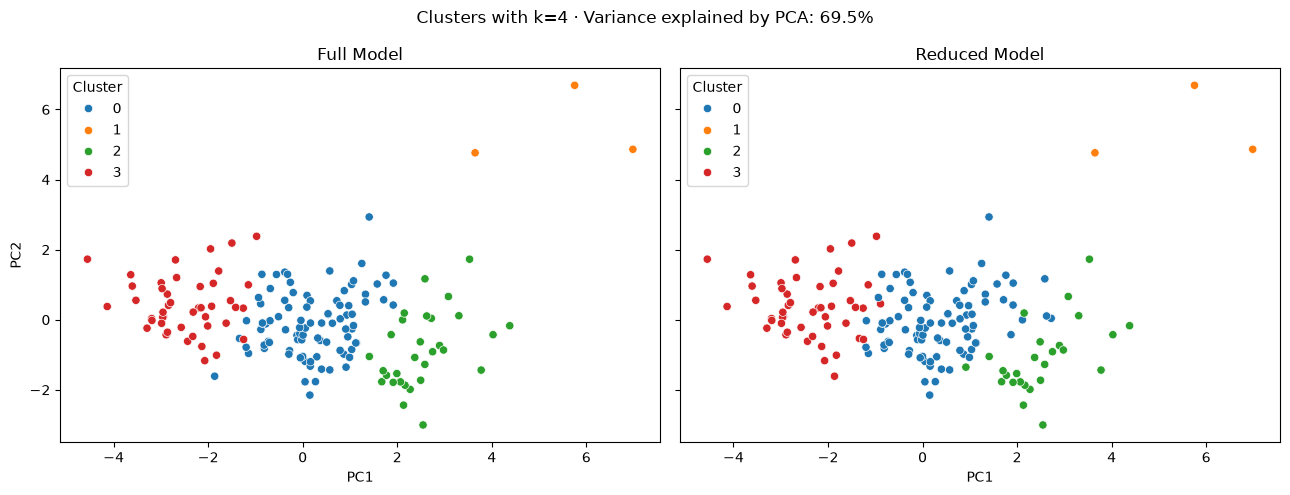

In [16]:


# Use the same axes to compare both models.
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_scaled)

grafico = results.copy()
grafico["PC1"] = coordenadas[:, 0]
grafico["PC2"] = coordenadas[:, 1]

# Map the reduced model's cluster labels to the full model's labels.
equivalencias = {2: 0, 3: 1, 1: 2, 0: 3}
grafico["reduced_alineado"] = grafico["reduced_clusters"].map(equivalencias)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for eje, columna, titulo in zip(
    ejes,
    ["clusters", "reduced_alineado"],
    ["Full Model", "Reduced Model"]
):
    sns.scatterplot(
        data=grafico,
        x="PC1",
        y="PC2",
        hue=columna,
        hue_order=[0, 1, 2, 3],
        palette="tab10",
        ax=eje
    )
    eje.set_title(titulo)
    eje.legend(title="Cluster")

varianza = pca.explained_variance_ratio_.sum()
fig.suptitle(f"Clusters with k=4 · Variance explained by PCA: {varianza:.1%}")
plt.tight_layout()
plt.show()

Both plots use the same PCA projection, calculated from the eight standardized indicators. The first two principal components explain **69.5% of the variance** in those data. Each country appears in the same position in both plots, and colors represent matched clusters. A change in color therefore indicates a different cluster assignment.

The three countries in the trade cluster stand out in the upper-right corner of both plots. The other groups are arranged mainly from left to right, with some overlap around the intermediate group. PCA is used for visualization. Each K-means model was trained on its corresponding set of standardized indicators before the countries were projected into two dimensions.

### Conclusion

The final model is **K-means with four clusters and six standardized indicators**: `child_mort`, `exports`, `health`, `imports`, `life_expec`, and `gdpp`. I chose this version because, despite its slightly lower silhouette score, it preserves the broad profiles of the full model and agrees with it on **94.61%** of country assignments after matching the cluster labels. This makes it possible to describe similar groups using two fewer indicators.

The analysis identifies four profiles: an intermediate group, a group with high incomes and low child mortality, a group with higher child mortality and lower life expectancy, and a group of three countries with particularly high trade activity relative to GDP. These groups depend on the indicators and scaling used, so they should be interpreted as descriptions of the dataset rather than fixed categories of countries.

As a next step, I would test hierarchical clustering using the same standardized indicators to see whether Luxembourg, Malta, and Singapore also form a distinct cluster under a different algorithm. This would help assess whether the trade profile persists when the clustering method changes.